# RetailPulse - Supermarket Sales Performance Analysis

**QUESTION.** Which branch, product line, payment mix and hour should a 3-store chain prioritize for staffing and promotions?

**WINDOW.** 1 January 2019 - 30 March 2019

**ROLE.** Analyst reporting to the Head of the Store Operations

**STACK.** pandas-numpy-seaborn-matplotlib


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style='whitegrid', palette="muted")
plt.rcParams["figure.figsize"]=(10,5)
plt.rcParams["figure.dpi"]=120



In [3]:
sales_raw=pd.read_csv("../data/supermarket_sales_raw.csv")

In [4]:
print("shape:", sales_raw.shape)

shape: (1012, 17)


In [5]:
print("First 5 rows:\n")
sales_raw.head()

First 5 rows:



,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,INV-10113,B,Mandalay,Normal,Male,Sports and travel,58.02,6,17.41,365.53,01/27/2019,20:51,Cash,348.12,4.761905,17.41,4.4
1,INV-10795,A,Yangon,Member,Male,Sports and travel,33.98,4,6.80,142.72,03/16/2019,16:19,Cash,135.92,4.761905,6.80,6.4
2,INV-10817,B,Mandalay,Member,Male,Food and beverages,38.03,3,5.70,119.79,01/27/2019,12:35,Credit card,114.09,4.761905,5.70,6.0
3,INV-10510,A,Yangon,Member,Female,Health and beauty,53.55,6,16.06,337.36,01/29/2019,18:36,Credit card,321.30,4.761905,16.06,6.7
4,INV-10492,B,Mandalay,Normal,Female,Health and beauty,78.96,1,3.95,82.91,01/01/2019,18:08,Ewallet,78.96,4.761905,3.95,4.8


In [6]:
print("Column wise dtypes")
print(sales_raw.dtypes)

Column wise dtypes
Invoice ID                     str
Branch                         str
City                           str
Customer type                  str
Gender                         str
Product line                   str
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Total                      float64
Date                           str
Time                           str
Payment                        str
cogs                       float64
gross margin percentage    float64
gross income               float64
Rating                     float64
dtype: object


In [7]:
print("Missing values per column:\n")
print(sales_raw.isna().sum())

Missing values per column:

Invoice ID                 0
Branch                     0
City                       0
Customer type              8
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     6
dtype: int64


In [8]:
print("Duplicate rows:\n")
print(sales_raw.duplicated().sum())

Duplicate rows:

12


In [9]:
print("Numeric summary:\n")
print(sales_raw.describe().round(2))

Numeric summary:

       Unit price  Quantity   Tax 5%    Total     cogs  gross margin percentage  gross income   Rating
count     1012.00   1012.00  1012.00  1012.00  1012.00                  1012.00       1012.00  1006.00
mean        50.60      5.39    13.70   287.62   273.92                     4.76         13.70     7.02
std         20.93      2.98     9.76   204.97   195.21                     0.00          9.76     1.72
min         13.38    -10.00   -29.20  -613.12  -583.92                     4.76        -29.20     4.00
25%         33.47      3.00     6.20   130.16   123.96                     4.76          6.20     5.50
50%         48.29      5.00    11.49   241.26   229.78                     4.76         11.49     7.00
75%         66.18      8.00    19.34   406.27   386.93                     4.76         19.34     8.50
max        101.22     10.00    45.31   951.52   906.21                     4.76         45.31    10.00


In [10]:
sales=sales_raw.copy()

In [11]:
print("Rows before cleaning:", len(sales))

Rows before cleaning: 1012


In [12]:
before= len(sales)
sales= sales.drop_duplicates()
after= len(sales)
print(f"Dropped {before-after} duplicate rows")

Dropped 12 duplicate rows


In [13]:
print(f"Now {after} rows")

Now 1000 rows


In [14]:
sales["City"]=sales["City"].astype(str).str.strip().str.title()

In [15]:
sales["Payment"]=sales["Payment"].astype(str).str.strip().str.title()

In [16]:
print("Unique Cities: ", sales["City"].unique())

Unique Cities:  <StringArray>
['Mandalay', 'Yangon', 'Naypyitaw']
Length: 3, dtype: str


In [17]:
print("Unique Payment Types: ", sales["Payment"].unique())

Unique Payment Types:  <StringArray>
['Cash', 'Credit Card', 'Ewallet']
Length: 3, dtype: str


In [18]:
print("Negative quantity rows: ", (sales["Quantity"]<0).sum())

Negative quantity rows:  3


In [19]:
sales=sales[sales["Quantity"]>0].copy()

In [20]:
print("Rows after dropping returns: ", len(sales))

Rows after dropping returns:  997


In [21]:
print(f"Customer type missing: {sales["Customer type"].isna().sum()}")

Customer type missing: 8


In [22]:
sales["Customer type"]=sales["Customer type"].fillna("Unknown")

In [23]:
median_rating=sales["Rating"].median()

In [24]:
print("Missing Ratings: ", sales["Rating"].isna().sum())

Missing Ratings:  6


In [25]:
sales["Rating"]=sales["Rating"].fillna(median_rating)

In [26]:
print("Missing values remaining: ")
print(sales.isna().sum())

Missing values remaining: 
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64


In [27]:
sales.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,INV-10113,B,Mandalay,Normal,Male,Sports and travel,58.02,6,17.41,365.53,01/27/2019,20:51,Cash,348.12,4.761905,17.41,4.4
1,INV-10795,A,Yangon,Member,Male,Sports and travel,33.98,4,6.80,142.72,03/16/2019,16:19,Cash,135.92,4.761905,6.80,6.4
2,INV-10817,B,Mandalay,Member,Male,Food and beverages,38.03,3,5.70,119.79,01/27/2019,12:35,Credit Card,114.09,4.761905,5.70,6.0
3,INV-10510,A,Yangon,Member,Female,Health and beauty,53.55,6,16.06,337.36,01/29/2019,18:36,Credit Card,321.30,4.761905,16.06,6.7
4,INV-10492,B,Mandalay,Normal,Female,Health and beauty,78.96,1,3.95,82.91,01/01/2019,18:08,Ewallet,78.96,4.761905,3.95,4.8


In [28]:
sales.shape

(997, 17)

In [29]:
sales["date"]= pd.to_datetime(sales["Date"], format="%m/%d/%Y")

In [30]:
sales["hour"]=pd.to_datetime(sales["Time"], format="%H:%M").dt.hour

In [31]:
sales["Day"]=sales["date"].dt.day_name()

In [32]:
sales["Month"]=sales["date"].dt.month_name()

In [33]:
sales.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating,date,hour,Day,Month
0,INV-10113,B,Mandalay,Normal,Male,Sports and travel,58.02,6,17.41,365.53,01/27/2019,20:51,Cash,348.12,4.761905,17.41,4.4,2019-01-27,20,Sunday,January
1,INV-10795,A,Yangon,Member,Male,Sports and travel,33.98,4,6.80,142.72,03/16/2019,16:19,Cash,135.92,4.761905,6.80,6.4,2019-03-16,16,Saturday,March
2,INV-10817,B,Mandalay,Member,Male,Food and beverages,38.03,3,5.70,119.79,01/27/2019,12:35,Credit Card,114.09,4.761905,5.70,6.0,2019-01-27,12,Sunday,January
3,INV-10510,A,Yangon,Member,Female,Health and beauty,53.55,6,16.06,337.36,01/29/2019,18:36,Credit Card,321.30,4.761905,16.06,6.7,2019-01-29,18,Tuesday,January
4,INV-10492,B,Mandalay,Normal,Female,Health and beauty,78.96,1,3.95,82.91,01/01/2019,18:08,Ewallet,78.96,4.761905,3.95,4.8,2019-01-01,18,Tuesday,January


In [34]:
revenue=sales["Total"].sum()
print("Gross revenue (incl. tax): ", revenue)

Gross revenue (incl. tax):  289817.99


In [35]:
profit= sales["gross income"].sum()
print("The gross profit is : ", profit)

The gross profit is :  13801.01


In [36]:
tickets=sales["Invoice ID"].nunique()
print ("Number of unique invoices : ", tickets)

Number of unique invoices :  997


In [37]:
qty= sales["Quantity"].sum()
print("Total quantity sold: ", qty)

Total quantity sold:  5439


In [38]:
aov=sales["Total"].mean()
print("AOV: ", aov)

AOV:  290.6900601805416


In [39]:
avg_rating=sales["Rating"].mean()
print("Average rating: ", avg_rating)

Average rating:  7.014242728184555


In [40]:
date_lower_limit=sales["date"].min().date()

In [41]:
date_upper_limit=sales["date"].max().date()

In [42]:
print(f"The range for dates is {date_lower_limit} to {date_upper_limit}")

The range for dates is 2019-01-01 to 2019-03-30


In [43]:
product=(
    sales.groupby("Product line" , as_index=False)
    .agg(
        Revenue=("Total" , "sum"),
        Orders=("Invoice ID", "nunique"),
        Units=("Quantity" ,"sum"),
        Avg_rating=("Rating", "mean"),
        Gross_income=("gross income","sum")
    ).sort_values("Revenue", ascending=False)
)

In [44]:
product

,Product line,Revenue,Orders,Units,Avg_rating,Gross_income
1,Fashion accessories,59170.49,184,1044,6.814130,2817.70
0,Electronic accessories,54623.66,157,813,7.133121,2601.16
5,Sports and travel,52383.82,162,863,7.067901,2494.50
2,Food and beverages,44573.05,203,1124,6.899015,2122.60
3,Health and beauty,41366.45,150,842,6.942000,1969.84
4,Home and lifestyle,37700.52,141,753,7.324113,1795.21


In [45]:
product["Revenue_share_%"]=((product["Revenue"]/product["Revenue"].sum())*100).round(2)
product["Avg_rating"]=product["Avg_rating"].round(2)

In [46]:
product

,Product line,Revenue,Orders,Units,Avg_rating,Gross_income,Revenue_share_%
1,Fashion accessories,59170.49,184,1044,6.81,2817.70,20.42
0,Electronic accessories,54623.66,157,813,7.13,2601.16,18.85
5,Sports and travel,52383.82,162,863,7.07,2494.50,18.07
2,Food and beverages,44573.05,203,1124,6.90,2122.60,15.38
3,Health and beauty,41366.45,150,842,6.94,1969.84,14.27
4,Home and lifestyle,37700.52,141,753,7.32,1795.21,13.01


In [47]:
order = product.sort_values("Revenue")

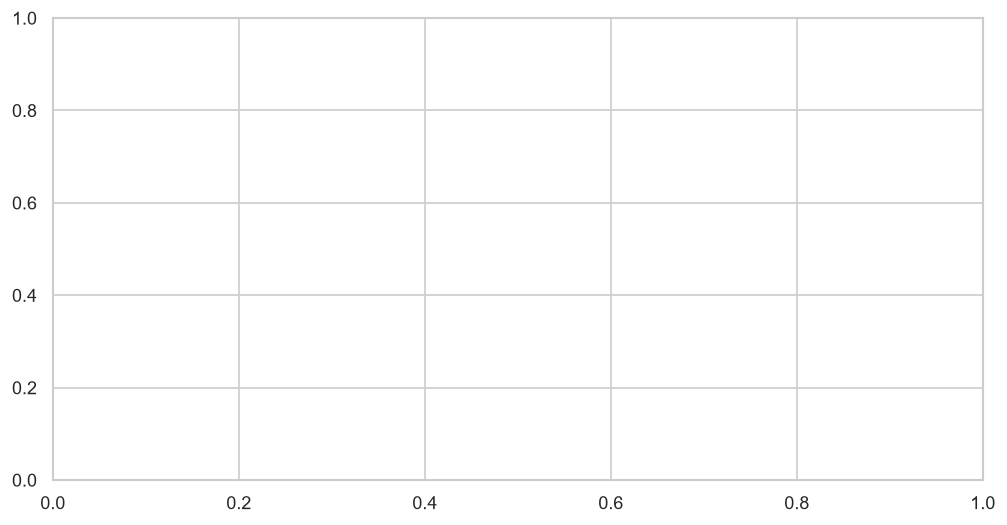

In [48]:
fig, ax=plt.subplots()

In [49]:
ax.barh(
    order["Product line"],
    order["Revenue"],
    color= sns.color_palette("Blues_d", len(order))
)

<BarContainer object of 6 artists>

In [50]:
ax.set_xlabel("Revenue (incl. tax)")

Text(0.5, 5.333333333333337, 'Revenue (incl. tax)')

In [51]:
ax.set_title("Revenue by Product line")

Text(0.5, 1.0, 'Revenue by Product line')

In [52]:
order


,Product line,Revenue,Orders,Units,Avg_rating,Gross_income,Revenue_share_%
4,Home and lifestyle,37700.52,141,753,7.32,1795.21,13.01
3,Health and beauty,41366.45,150,842,6.94,1969.84,14.27
2,Food and beverages,44573.05,203,1124,6.90,2122.60,15.38
5,Sports and travel,52383.82,162,863,7.07,2494.50,18.07
0,Electronic accessories,54623.66,157,813,7.13,2601.16,18.85
1,Fashion accessories,59170.49,184,1044,6.81,2817.70,20.42


In [53]:
for y,v in enumerate(order["Revenue"]):
    ax.text(v+80, y, f"${v:,.0f}", va="center", fontsize=8)


In [54]:
fig.tight_layout()

In [55]:
fig.savefig("../figures/01_revenue_by_product.png", dpi=140)

In [56]:
sales.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating,date,hour,Day,Month
0,INV-10113,B,Mandalay,Normal,Male,Sports and travel,58.02,6,17.41,365.53,01/27/2019,20:51,Cash,348.12,4.761905,17.41,4.4,2019-01-27,20,Sunday,January
1,INV-10795,A,Yangon,Member,Male,Sports and travel,33.98,4,6.80,142.72,03/16/2019,16:19,Cash,135.92,4.761905,6.80,6.4,2019-03-16,16,Saturday,March
2,INV-10817,B,Mandalay,Member,Male,Food and beverages,38.03,3,5.70,119.79,01/27/2019,12:35,Credit Card,114.09,4.761905,5.70,6.0,2019-01-27,12,Sunday,January
3,INV-10510,A,Yangon,Member,Female,Health and beauty,53.55,6,16.06,337.36,01/29/2019,18:36,Credit Card,321.30,4.761905,16.06,6.7,2019-01-29,18,Tuesday,January
4,INV-10492,B,Mandalay,Normal,Female,Health and beauty,78.96,1,3.95,82.91,01/01/2019,18:08,Ewallet,78.96,4.761905,3.95,4.8,2019-01-01,18,Tuesday,January


In [57]:
branch=(
    sales.groupby("Branch", as_index=False)
    .agg(Revenue=("Total" , "sum"),
        Orders=("Invoice ID", "nunique"),
        Units=("Quantity" ,"sum"),
        Avg_rating=("Rating", "mean"),
        Gross_income=("gross income","sum"),
        AOV=("Total", "mean")
    ).sort_values("Revenue", ascending=False)
)

In [58]:
branch["Revenue_share_%"]=((branch["Revenue"]/branch["Revenue"].sum())*100).round(2)
branch["Avg_rating"]=branch["Avg_rating"].round(2)

In [59]:
branch

,Branch,Revenue,Orders,Units,Avg_rating,Gross_income,AOV,Revenue_share_%
0,A,117428.57,384,2163,7.05,5591.94,305.803568,40.52
1,B,89914.82,328,1710,6.99,4281.74,274.130549,31.02
2,C,82474.60,285,1566,7.00,3927.33,289.384561,28.46


In [60]:
branches=["A", "B", "C"]
revenue_share=[40.52,31.02,28.46]

Text(0.5, 1.0, 'Revenue share of each branch')

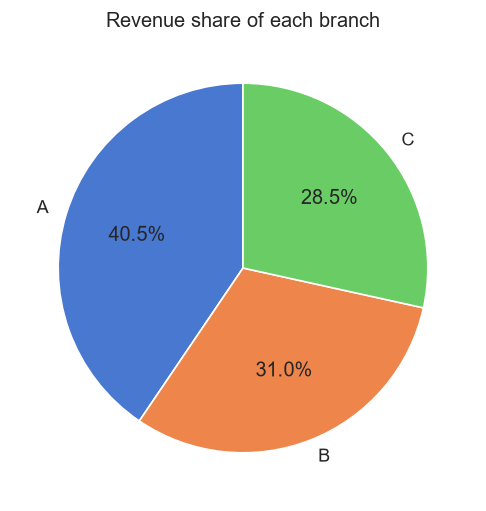

In [61]:
fig2=plt.pie(
    revenue_share,
    labels=branches,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Revenue share of each branch")


In [62]:
types_of_customers=(
    sales.groupby("Customer type", as_index=False)
    .agg(Revenue=("Total" , "sum"),
        Orders=("Invoice ID", "nunique"),
        Units=("Quantity" ,"sum"),
        Avg_rating=("Rating", "mean"),
        Gross_income=("gross income","sum"),
        AOV=("Total", "mean")
    ).sort_values("Revenue", ascending=False)

)

In [63]:
types_of_customers["Revenue_share_%"]=((types_of_customers["Revenue"]/types_of_customers["Revenue"].sum())*100).round(2)
types_of_customers["Avg_rating"]=types_of_customers["Avg_rating"].round(2)

In [64]:
types_of_customers

,Customer type,Revenue,Orders,Units,Avg_rating,Gross_income,AOV,Revenue_share_%
0,Member,150034.18,517,2861,7.05,7144.56,290.201509,51.77
1,Normal,137370.37,472,2534,6.99,6541.52,291.038919,47.40
2,Unknown,2413.44,8,44,6.32,114.93,301.680000,0.83


Text(0.5, 1.0, 'Revenue by Customer Type')

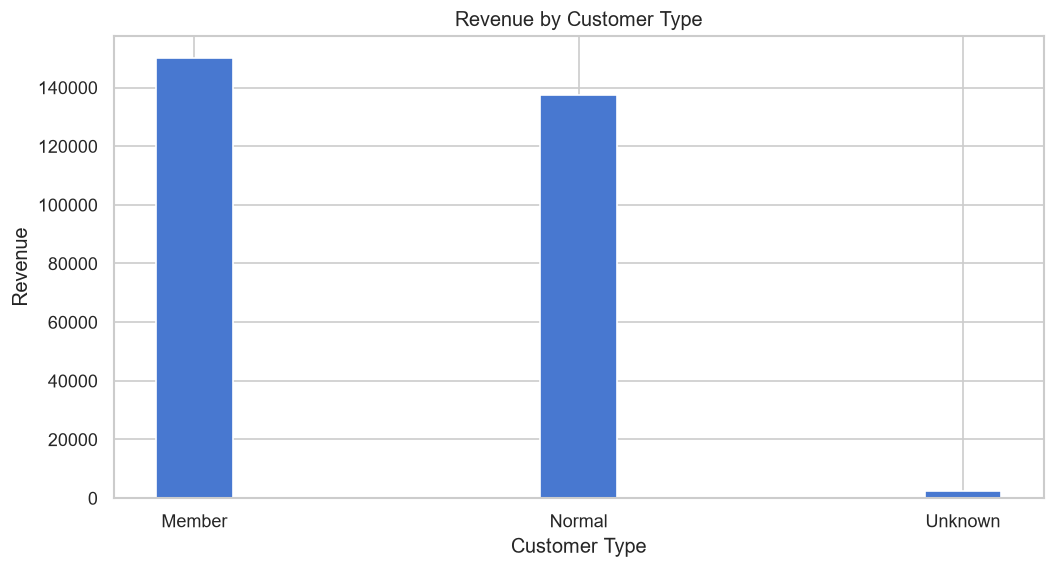

In [65]:
x=["Member","Normal", "Unknown"]
y=[150034.18,137370.37,2413.44]

plt.bar(x, y, width=0.2)
plt.xlabel("Customer Type")
plt.ylabel("Revenue")
plt.title("Revenue by Customer Type")


In [66]:
genders= (
    sales.groupby("Gender", as_index=False)
    .agg(
        Revenue=("Total" , "sum"),
        Orders=("Invoice ID", "nunique"),
        Units=("Quantity" ,"sum"),
        Avg_rating=("Rating", "mean"),
        Gross_income=("gross income","sum"),
        AOV=("Total", "mean")
    ).sort_values("Revenue", ascending=False)
        )


In [67]:
genders["Revenue_share_%"]=((genders["Revenue"]/genders["Revenue"].sum())*100).round(2)
genders["Avg_rating"]=genders["Avg_rating"].round(2)

In [68]:
genders

,Gender,Revenue,Orders,Units,Avg_rating,Gross_income,AOV,Revenue_share_%
0,Female,150978.78,518,2840,6.98,7189.53,291.464826,52.09
1,Male,138839.21,479,2599,7.05,6611.48,289.852213,47.91


In [69]:
genders=["Female", "Male"]
revenue_share=[52.09,47.91]

Text(0.5, 1.0, 'Revenue share of each gender')

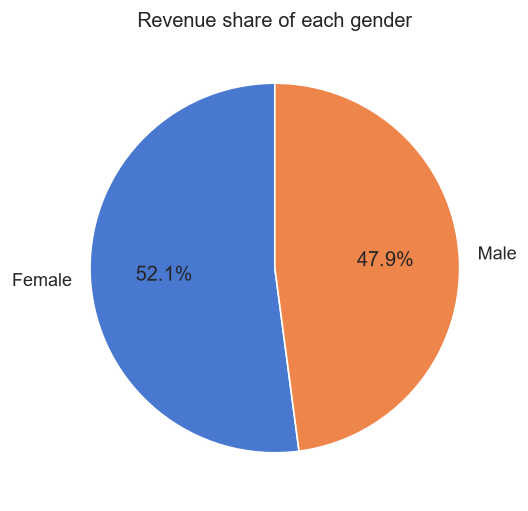

In [70]:
plt.pie(
    revenue_share,
    labels=genders,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Revenue share of each gender")

    
    


In [71]:
payment_mix= (
    sales.groupby("Payment", as_index=False)
    .agg(
        Revenue=("Total" , "sum"),
        Orders=("Invoice ID", "nunique"),
        Units=("Quantity" ,"sum"),
        Avg_rating=("Rating", "mean"),
        Gross_income=("gross income","sum")
    ).sort_values("Revenue", ascending=False)
        )


In [72]:
payment_mix["Revenue_share_%"]=((payment_mix["Revenue"]/payment_mix["Revenue"].sum())*100).round(2)
payment_mix["Avg_rating"]=payment_mix["Avg_rating"].round(2)

In [73]:
payment_mix

,Payment,Revenue,Orders,Units,Avg_rating,Gross_income,Revenue_share_%
0,Cash,107115.04,369,2019,7.02,5100.78,36.96
2,Ewallet,95470.94,336,1778,6.97,4546.29,32.94
1,Credit Card,87232.01,292,1642,7.06,4153.94,30.10


Text(0.5, 1.0, 'Revenue by Payment Type')

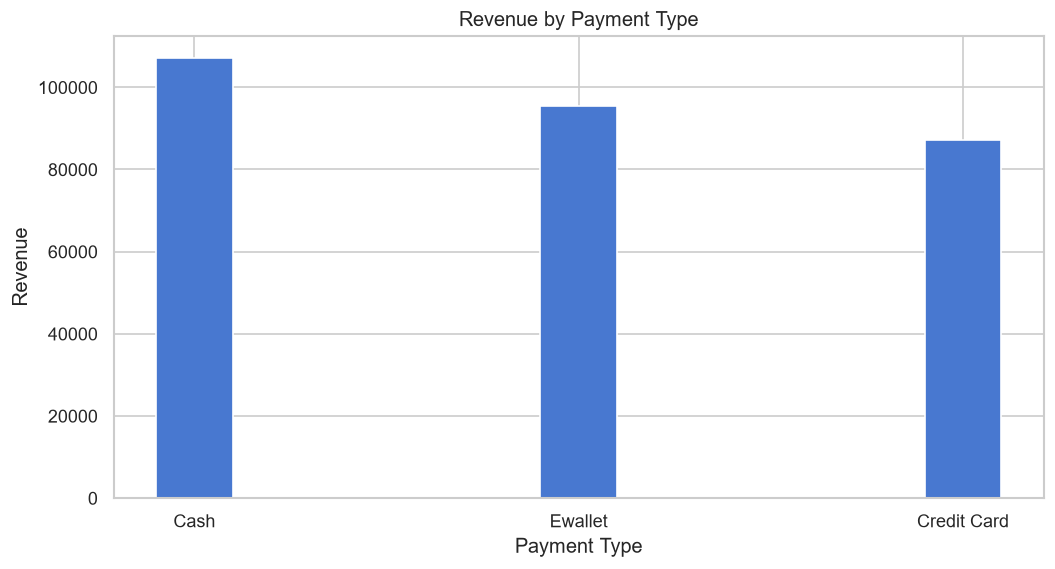

In [74]:
x=["Cash","Ewallet", "Credit Card"]
y=[107115.04,95470.94,87232.01	]

plt.bar(x, y, width=0.2)
plt.xlabel("Payment Type")
plt.ylabel("Revenue")
plt.title("Revenue by Payment Type")
